## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Eyram Golo

**Date:**10/21/2026

In [7]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

token_freq[:20]

[('new', 1365),
 ('date', 1202),
 ('get', 1052),
 ('please', 1022),
 ('enron', 927),
 ('like', 923),
 ('2002', 869),
 ('would', 806),
 ('one', 798),
 ('message', 795),
 ('call', 740),
 ('free', 691),
 ('software', 680),
 ('dear', 651),
 ('know', 644),
 ('email', 629),
 ('url:', 625),
 ('time', 609),
 ('start', 604),
 ('linguistics', 598)]

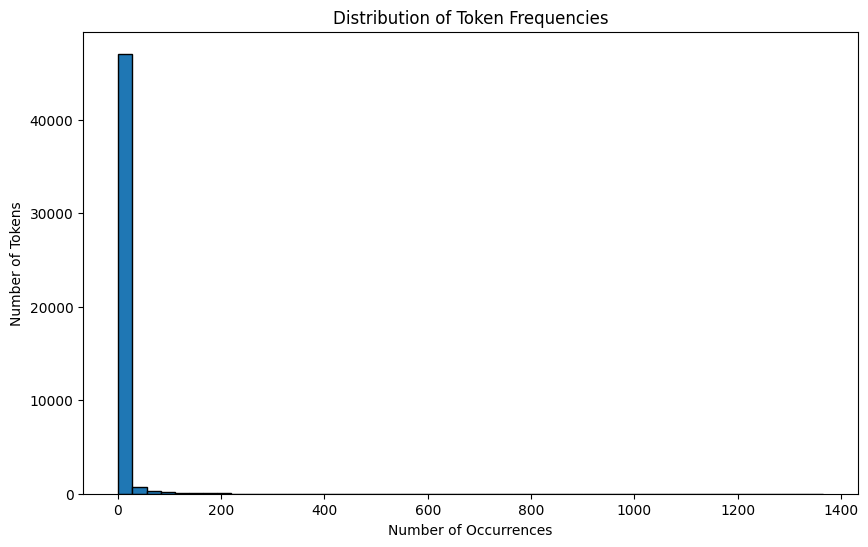

In [8]:
import matplotlib.pyplot as plt

# Get the frequency of each unique token
frequencies = list(token_count.values())

# Plot histogram
plt.figure(figsize=(10, 6))
plt.hist(frequencies, bins=50, edgecolor='black')

plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens')
plt.title('Distribution of Token Frequencies')

plt.show()

The histogram is heavily right-skewed. Most tokens appear only a few times, while a small number of tokens occur very frequently. We can see this because most of the data is concentrated on the left side of the graph, with a long tail extending to the right. This shows that a few words are used repeatedly across the emails, while most words are uncommon.

In [1]:
import pandas as pd

# Load the phishing email dataset
df = pd.read_parquet('Phishing_clean.parquet')

# Check the dimensions
print("Dataset shape:", df.shape)

# Preview the first 5 rows
df.head()

Dataset shape: (18634, 2712)


,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [2]:
print(df['Email Type'].value_counts())

Email Type
0    11322
1     7312
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

# Separate the features from the outcome variable
X = df.drop(columns=['Email Type'])
y = df['Email Type']

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Check the sizes
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (14907, 2711)
Test set: (3727, 2711)


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Create and train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Calculate R-squared
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training R²:", train_r2)
print("Test R²:", test_r2)

Training R²: 0.7670143724934355
Test R²: 0.6658718438847919


q2.2
The linear regression model had an R² of 0.7670 on the training set and 0.6659 on the test set. This means the model explained about 76.7% of the variation in the training data and 66.6% in the test data. The higher training R² suggests some overfitting, but the model still performs reasonably well on unseen emails.

In [5]:
# Create a dataframe of words and their coefficients
coef_df = pd.DataFrame({
    'Word': X.columns,
    'Coefficient': model.coef_
})

# Calculate absolute values
coef_df['Absolute Coefficient'] = coef_df['Coefficient'].abs()

# Sort by largest absolute coefficient
coef_df = coef_df.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

# Display top 20 words
coef_df.head(20)

,Word,Coefficient,Absolute Coefficient
835,intervention,-1.259257,1.259257
740,localized,0.824350,0.824350
2362,thermal,0.747006,0.747006
851,crawler,0.696167,0.696167
1504,background-image:,-0.622909,0.622909
1406,"helvetica,",0.598560,0.598560
906,aging,0.594956,0.594956
1839,form.,0.576886,0.576886
2242,gray;,-0.574480,0.574480
1552,a:active,0.574480,0.574480


q2.3
The words with the largest coefficients in absolute value were "intervention," "localized," "thermal," "crawler," and "background-image:". Intervention had the largest negative coefficient (-1.2593), suggesting that its presence is associated with an email being less likely to be classified as a scam. Words like localized, thermal, and crawler had positive coefficients, meaning they were associated with higher scam predictions. Overall, these words had the strongest influence on the model's predictions based on their coefficient sizes.

In [6]:
from sklearn.decomposition import PCA

# Create PCA with 2 components
pca = PCA(n_components=2)

# Apply PCA to the token features
X_pca = pca.fit_transform(X)

# Create a dataframe for plotting
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

# Add email type
pca_df['Email Type'] = y.to_numpy()

# Preview the data
pca_df.head()

,PC1,PC2,Email Type
0,-0.009828,-0.075946,0
1,-0.023373,-0.006370,0
2,-0.047556,0.437420,0
3,-0.089297,0.208532,1
4,-0.076827,0.112954,1


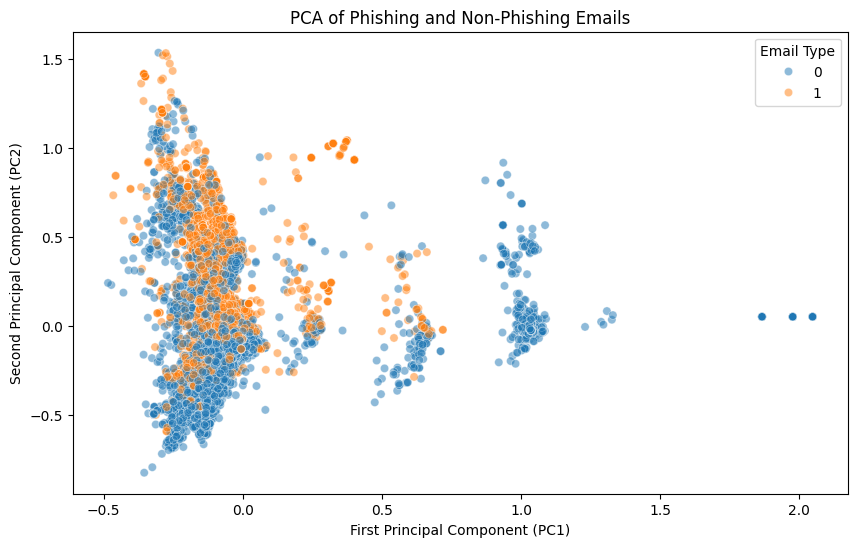

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Email Type',
    alpha=0.5
)

plt.title('PCA of Phishing and Non-Phishing Emails')
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.legend(title='Email Type')
plt.show()

q3.
The scatter plot shows that phishing and non-phishing emails overlap quite a bit, especially in the main cluster on the left. However, there are some noticeable differences in how the two groups are distributed. Phishing emails appear more concentrated in the upper portion of the main cluster, while some smaller clusters on the right contain mostly non-phishing emails. Overall, the first two principal components capture some patterns in the data, but they do not clearly separate phishing from non-phishing emails.

In [8]:
from sklearn.decomposition import PCA

# PCA with 2610 components
pca_2610 = PCA(n_components=2610, svd_solver='randomized', random_state=42)

# Fit PCA on training data
X_train_pca = pca_2610.fit_transform(X_train)

# Transform test data
X_test_pca = pca_2610.transform(X_test)

print("Training PCA shape:", X_train_pca.shape)
print("Test PCA shape:", X_test_pca.shape)

Training PCA shape: (14907, 2610)
Test PCA shape: (3727, 2610)


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Train linear regression using PCA components
pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

# Make predictions
y_train_pca_pred = pca_model.predict(X_train_pca)
y_test_pca_pred = pca_model.predict(X_test_pca)

# Calculate R-squared
pca_train_r2 = r2_score(y_train, y_train_pca_pred)
pca_test_r2 = r2_score(y_test, y_test_pca_pred)

print("PCA Training R²:", pca_train_r2)
print("PCA Test R²:", pca_test_r2)

PCA Training R²: 0.7661790402020929
PCA Test R²: 0.668449827853717


In [10]:
comparison = pd.DataFrame({
    'Model': ['Original Linear Regression', 'PCA Linear Regression'],
    'Training R²': [train_r2, pca_train_r2],
    'Test R²': [test_r2, pca_test_r2]
})

comparison

,Model,Training R²,Test R²
0,Original Linear Regression,0.767014,0.665872
1,PCA Linear Regression,0.766179,0.668450


q5The main advantage of using PCA is that it reduces the number of variables while keeping most of the important information in the data. Since the email dataset contains thousands of word features, using all of them can make regression more complicated. PCA combines the original features into fewer components that are not correlated with each other, which can help reduce multicollinearity and make the model more manageable. In this case, PCA also slightly improved the test R², showing that it can help the model perform a little better on new data.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [9]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]